# Problem 2: exploring the stage-1 dataset (`project2_minival`)

This notebook looks at what the **second stage** of the detector receives. The first stage (OpenPCDet's pretrained PointRCNN, run on KITTI) has already processed every scene. For each frame it saved:

| Key | Shape | What it is |
|---|---|---|
| `xyz` | (16384, 3) | 16,384 LiDAR points, sampled from the full scan, in the **rectified camera-0 frame** |
| `intensity` | (16384,) | Reflectance of each point (like column 3 of `velodyne` in Problem 1) |
| `seg` | (16384,) | Stage-1 probability that the point belongs to a car |
| `features` | (16384, 128) | What stage 1 "learned" about each point: a 128-number description of its neighborhood |
| `detections` | (100, 15) | 100 **coarse car proposals** (boxes + score), padded with zero rows if there were fewer |
| `target` | (K, 15) | **Ground-truth** cars from KITTI `label_2` |

The second stage takes each proposal, collects the points and features around it (Task 2.2), and learns to correct the box and predict a better confidence score (Tasks 2.3–2.5).

`minival` is 250 random frames from the val split. It's small enough for a laptop. The large train and val splits stay on Leonardo for training.

**Coordinate frame reminder** (same as KITTI labels, see Problem 1): x → right, y → **down**, z → forward. The camera is about 1.65 m above the road, so the road is around y ≈ +1.65. In the plots, height is shown as `-y` so that "up" really points up.

In [6]:
import os
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
import shapely

np.set_printoptions(precision=3, suppress=True, linewidth=140)
plt.rcParams['figure.dpi'] = 110

DATA_DIR = '.'          # folder containing project2_minival.h5/.txt
SPLIT = 'minival'

h5 = h5py.File(os.path.join(DATA_DIR, f'project2_{SPLIT}.h5'), 'r')
frames = open(os.path.join(DATA_DIR, f'project2_{SPLIT}.txt')).read().split()
print(f'{len(frames)} frames, e.g. {frames[:5]}')
print(f'file size: {os.path.getsize(os.path.join(DATA_DIR, f"project2_{SPLIT}.h5")) / 1e9:.2f} GB\n')

g = h5[frames[6]]
print(f'Contents of one frame ({frames[6]}):')
print(pd.DataFrame([(k, g[k].shape, g[k].dtype, f'{g[k].nbytes / 1e6:.2f} MB') for k in g],
                   columns=['key', 'shape', 'dtype', 'size']).to_string(index=False))
print('\nframe attributes:', dict(g.attrs))

250 frames, e.g. ['000002', '000066', '000090', '000106', '000197']
file size: 1.13 GB

Contents of one frame (000308):
       key        shape   dtype    size
detections    (100, 15) float32 0.01 MB
  features (16384, 128) float16 4.19 MB
 intensity     (16384,) float32 0.07 MB
       seg     (16384,) float32 0.07 MB
    target      (2, 15) float32 0.00 MB
       xyz   (16384, 3) float32 0.20 MB

frame attributes: {'complete': np.int64(1), 'num_proposals': np.int64(100)}


## 1. Reading the data the way the template does

The course template reads frames through `DatasetLoader.get_data()` in `dataset.py`. Two things happen there:
* `detections` and `target` are reduced from the 15 KITTI columns to the **7 box parameters** `(x, y, z, h, w, l, ry)`, the format used by every task.
* All-zero padding rows of `detections` are removed.

`__getitem__` also calls `roi_pool` and `sample_proposals` (Tasks 2.2 and 2.3), which aren't implemented yet, so only `get_data` is used here.

In [ ]:
from dataset import DatasetLoader

ds = DatasetLoader({'root_dir': DATA_DIR}, SPLIT)
print(f'DatasetLoader sees {len(ds)} frames\n')

raw = h5[frames[0]]['detections'][()]
det = ds.get_data(0, 'detections')
print('raw detections        :', raw.shape, ' -> get_data:', det.shape)
print('raw target            :', h5[frames[0]]['target'].shape, ' -> get_data:', ds.get_data(0, 'target').shape)
print('\nfirst proposal, raw 15 columns:\n', raw[0])
print('same proposal from get_data (x, y, z, h, w, l, ry):\n', det[0])

DatasetLoader sees 250 frames

raw detections        : (100, 15)  -> get_data: (100, 7)
raw target            : (1, 15)  -> get_data: (1, 7)

first proposal, raw 15 columns:
 [  0.      0.      2.697 867.077 143.896 979.017 178.703   1.519   1.661   4.299  14.234  -0.083  31.832   3.116   0.751]
same proposal from get_data (x, y, z, h, w, l, ry):
 [ 3.372  2.437 34.224  1.387  1.569  3.695 -1.525]


In [4]:
KITTI_COLS = ['truncated', 'occluded', 'alpha', 'bbox_left', 'bbox_top', 'bbox_right', 'bbox_bottom',
              'h', 'w', 'l', 'x', 'y', 'z', 'rotation_y', 'score']

print('The 15 columns, ground truth of the first frame:')
pd.DataFrame(h5[frames[0]]['target'][()], columns=KITTI_COLS).round(2)

The 15 columns, ground truth of the first frame:


,truncated,occluded,alpha,bbox_left,bbox_top,bbox_right,bbox_bottom,h,w,l,x,y,z,rotation_y,score
0,0.0,0.0,-1.67,657.390015,190.130005,700.070007,223.389999,1.41,1.58,4.36,3.18,2.27,34.380001,-1.58,1.0


Columns 0–6 (truncation, occlusion, alpha, 2D box) aren't used by the network, but **the evaluation uses them**. `utils/eval.py` sorts each ground-truth car into KITTI's *easy / moderate / hard* levels from its 2D box height, occlusion and truncation (section 5).

## 2. Dataset overview: one row per frame

In [5]:
rows = []
for i, fr in enumerate(frames):
    g = h5[fr]
    xyz = g['xyz'][()]
    det = ds.get_data(i, 'detections')
    tgt = g['target'][()]
    rows.append({'frame': fr,
                 'cars (GT)': len(tgt),
                 'proposals': len(det),
                 'unique points': len(np.unique(xyz, axis=0)),
                 'max depth z [m]': xyz[:, 2].max(),
                 'points with seg > 0.5': int((g['seg'][()] > 0.5).sum())})
overview = pd.DataFrame(rows).set_index('frame')
overview['max proposal score'] = [h5[fr]['detections'][:, 14].max() for fr in frames]   # get_data drops the score column
overview.describe().round(2)

,cars (GT),proposals,unique points,max depth z [m],points with seg > 0.5,max proposal score
count,250.00,250.0,250.00,250.00,250.00,250.00
mean,3.74,100.0,16371.22,68.44,1107.79,0.87
std,3.13,0.0,128.95,4.68,1292.79,0.17
min,0.00,100.0,14685.00,30.74,0.00,0.27
25%,1.00,100.0,16384.00,69.35,101.25,0.85
50%,3.00,100.0,16384.00,69.94,593.50,0.95
75%,5.00,100.0,16384.00,70.08,1758.25,0.98
max,15.00,100.0,16384.00,70.16,5169.00,1.00


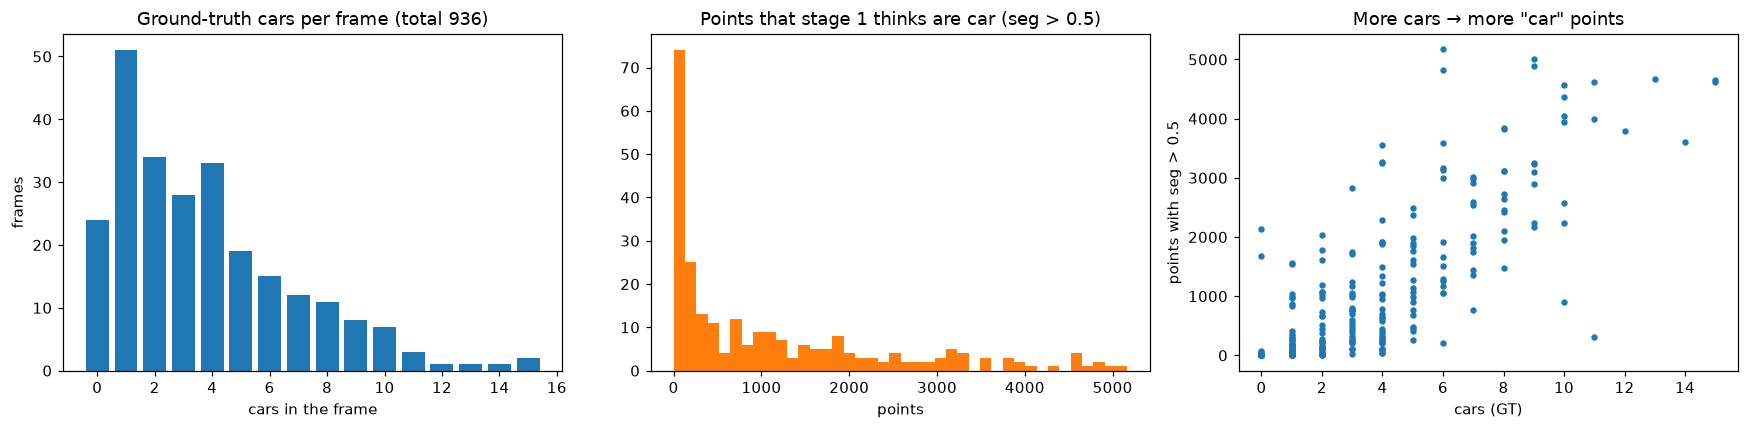

3 of 250 frames had fewer than 16,384 points in the camera view and were padded by repeating points:
frame
001180    14685
001925    15339
003531    15934


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
counts = overview['cars (GT)']
axes[0].bar(*np.unique(counts, return_counts=True), color='tab:blue')
axes[0].set_xlabel('cars in the frame'); axes[0].set_ylabel('frames'); axes[0].set_title(f'Ground-truth cars per frame (total {counts.sum()})')

axes[1].hist(overview['points with seg > 0.5'], bins=40, color='tab:orange')
axes[1].set_xlabel('points'); axes[1].set_title('Points that stage 1 thinks are car (seg > 0.5)')

axes[2].scatter(counts, overview['points with seg > 0.5'], s=10)
axes[2].set_xlabel('cars (GT)'); axes[2].set_ylabel('points with seg > 0.5')
axes[2].set_title('More cars → more "car" points')
plt.tight_layout(); plt.show()

padded = overview[overview['unique points'] < 16384]
print(f'{len(padded)} of {len(frames)} frames had fewer than 16,384 points in the camera view and were padded by '
      f'repeating points:\n{padded["unique points"].to_string()}')

## 3. One frame in detail

The frame below is used for the rest of the per-frame plots. Change `FRAME` to look at others (frames with many cars are listed at the end of the previous table).

In [9]:
FRAME = '002153'
idx = frames.index(FRAME)
g = h5[FRAME]
xyz, intensity, seg = g['xyz'][()], g['intensity'][()], g['seg'][()]
feat = g['features'][()].astype(np.float32)
det_raw = g['detections'][()]
det_raw = det_raw[np.abs(det_raw).sum(1) > 0]
det, det_score = ds.get_data(idx, 'detections'), det_raw[:, 14]
tgt = ds.get_data(idx, 'target')
print(f'frame {FRAME}: {len(xyz)} points, {len(tgt)} ground-truth cars, {len(det)} proposals\n')
print(pd.DataFrame(xyz, columns=['x (right)', 'y (down)', 'z (forward)']).describe().round(2))

frame 002153: 16384 points, 8 ground-truth cars, 100 proposals

       x (right)  y (down)  z (forward)
count   16384.00  16384.00     16384.00
mean        0.42      1.06        15.30
std         5.80      0.85        10.32
min       -10.77     -1.86         2.68
25%        -4.47      0.46         8.75
50%         0.79      1.38        12.19
75%         3.99      1.75        18.95
max        13.20      2.59        69.99


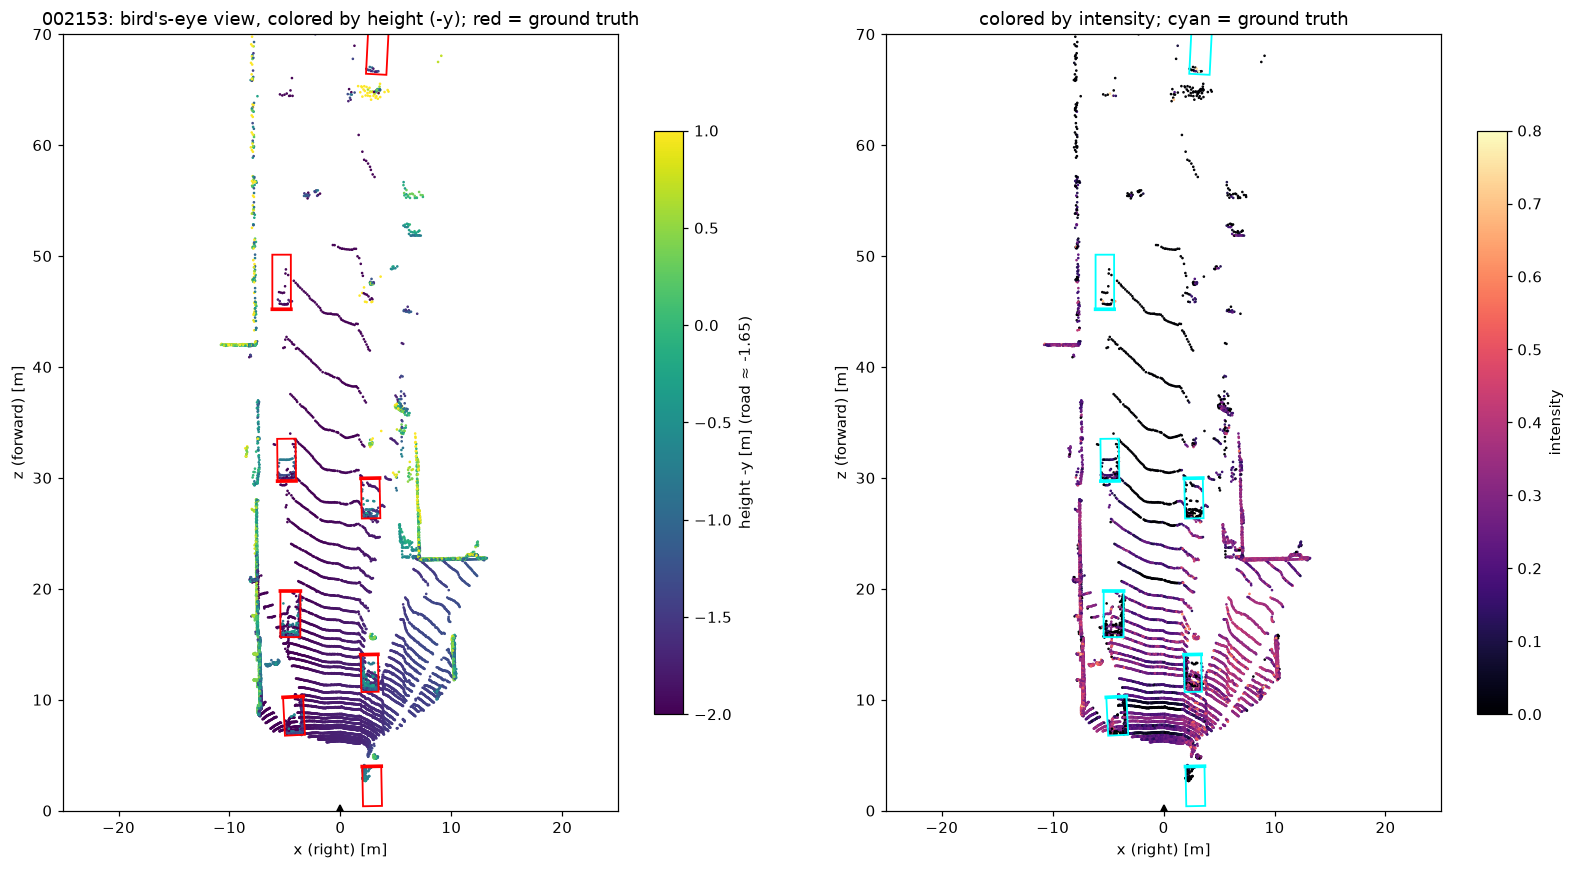

In [10]:
def box_corners(boxes):
    '''(N, 7) boxes (x, y, z, h, w, l, ry) in the camera frame -> (N, 8, 3) corners.
    Same convention as Problem 1: (x, y, z) is the bottom-face center, y points down.'''
    boxes = np.atleast_2d(boxes)
    out = []
    for x, y, z, h, w, l, ry in boxes:
        xs = np.array([ l,  l, -l, -l,  l,  l, -l, -l]) / 2
        ys = np.array([-h, -h, -h, -h,  0,  0,  0,  0])
        zs = np.array([-w,  w,  w, -w, -w,  w,  w, -w]) / 2
        R = np.array([[np.cos(ry), 0, np.sin(ry)], [0, 1, 0], [-np.sin(ry), 0, np.cos(ry)]])
        out.append((R @ np.vstack([xs, ys, zs])).T + [x, y, z])
    return np.array(out).reshape(-1, 8, 3)


def draw_bev_boxes(ax, boxes, color, lw=1.2, alpha=1.0, front=True):
    '''Bird's-eye view: corners 4-7 form the bottom face; the 4-5 edge is the front of the car.'''
    for c in box_corners(boxes):
        ax.add_patch(MplPolygon(c[[4, 5, 6, 7], :][:, [0, 2]], closed=True, fill=False, ec=color, lw=lw, alpha=alpha))
        if front:
            ax.plot(c[[4, 5], 0], c[[4, 5], 2], color=color, lw=lw * 2, alpha=alpha)


def bev(ax, title, xlim=(-25, 25), zlim=(0, 70)):
    ax.set_xlim(*xlim); ax.set_ylim(*zlim); ax.set_aspect('equal')
    ax.set_xlabel('x (right) [m]'); ax.set_ylabel('z (forward) [m]'); ax.set_title(title)
    ax.plot(0, 0, 'k^', ms=8)


fig, axes = plt.subplots(1, 2, figsize=(15, 8))
ax = axes[0]
sc = ax.scatter(xyz[:, 0], xyz[:, 2], c=-xyz[:, 1], s=0.5, cmap='viridis', vmin=-2, vmax=1)
draw_bev_boxes(ax, tgt, 'red')
bev(ax, f"{FRAME}: bird's-eye view, colored by height (-y); red = ground truth")
fig.colorbar(sc, ax=ax, label='height -y [m] (road ≈ -1.65)', fraction=0.04)

ax = axes[1]
sc = ax.scatter(xyz[:, 0], xyz[:, 2], c=intensity, s=0.5, cmap='magma', vmax=0.8)
draw_bev_boxes(ax, tgt, 'cyan')
bev(ax, 'colored by intensity; cyan = ground truth')
fig.colorbar(sc, ax=ax, label='intensity', fraction=0.04)
plt.tight_layout(); plt.show()

Only a wedge in front of the car is present: the first stage keeps **only points inside the camera's field of view** (as in Problem 1, Task 1.3), then samples 16,384 of them. Point density drops quickly with distance, so far cars have only a few points.

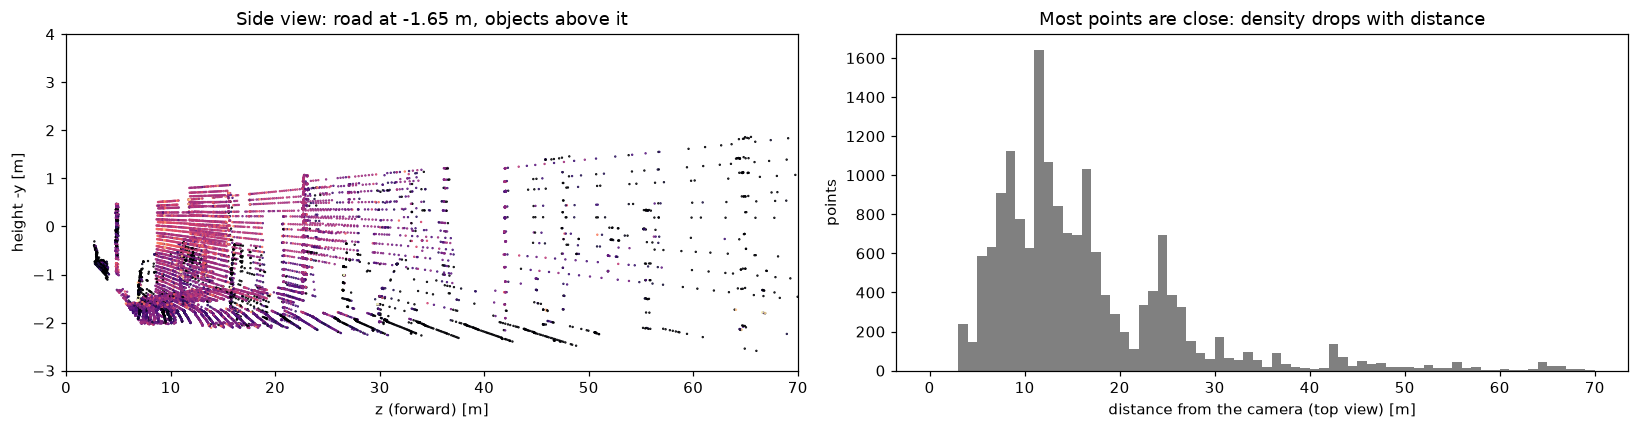

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].scatter(xyz[:, 2], -xyz[:, 1], c=intensity, s=0.3, cmap='magma', vmax=0.8)
axes[0].set_xlabel('z (forward) [m]'); axes[0].set_ylabel('height -y [m]'); axes[0].set_xlim(0, 70); axes[0].set_ylim(-3, 4)
axes[0].set_title('Side view: road at -1.65 m, objects above it')

dist = np.linalg.norm(xyz[:, [0, 2]], axis=1)
axes[1].hist(dist, bins=70, range=(0, 70), color='gray')
axes[1].set_xlabel('distance from the camera (top view) [m]'); axes[1].set_ylabel('points')
axes[1].set_title('Most points are close: density drops with distance')
plt.tight_layout(); plt.show()

## 4. `seg`: stage 1's point-wise car probability
#### ALERT: **This condition can be modified by adding the labels of cyclist and pedestrians, to predict these three or background**

The first stage is trained to do two jobs: label each point as car or background, and propose boxes from the car points. `seg` is that per-point probability.

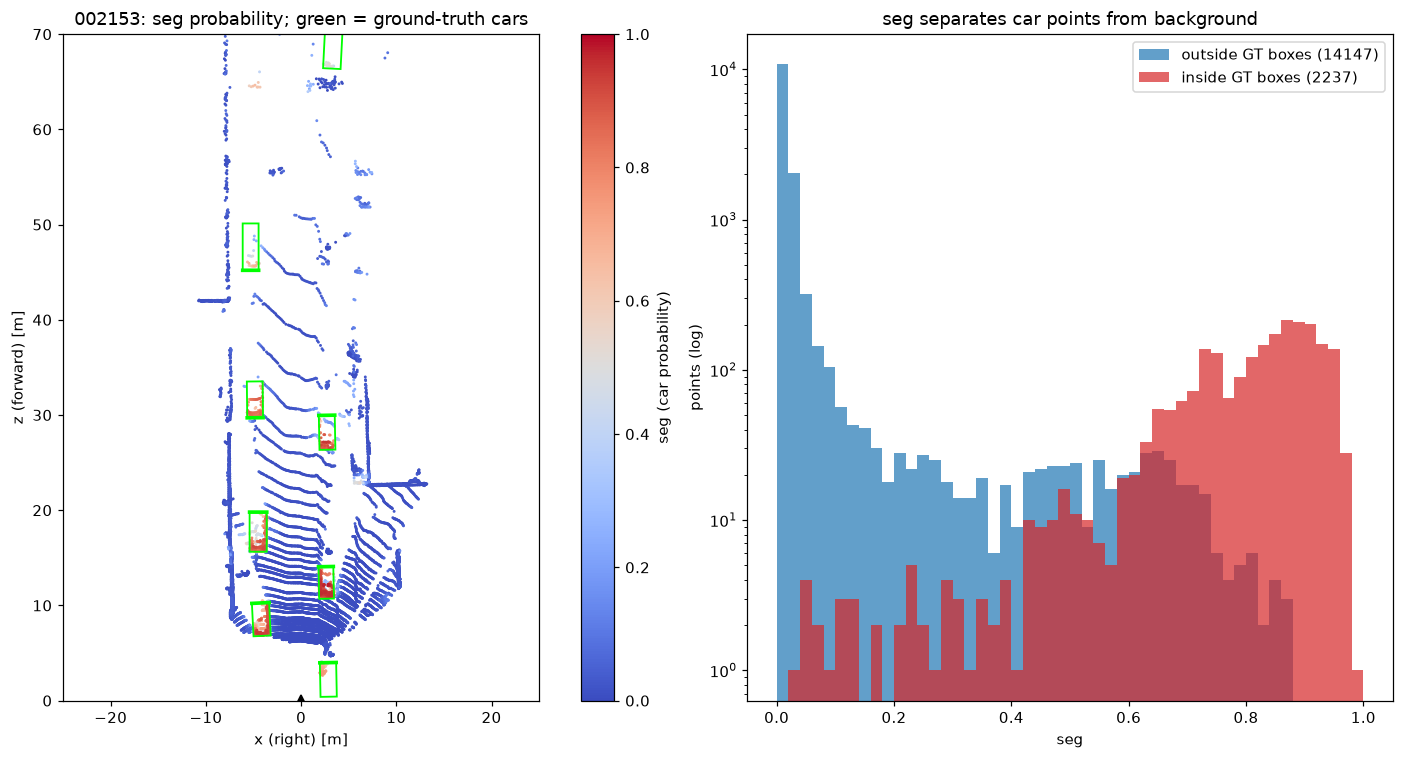

In [12]:
def points_in_boxes(points, boxes, enlarge=0.0):
    '''Boolean (N_points, N_boxes): point inside box (camera frame), optionally enlarged by `enlarge` meters on every side.'''
    inside = np.zeros((len(points), len(boxes)), bool)
    for j, (x, y, z, h, w, l, ry) in enumerate(np.atleast_2d(boxes)):
        R = np.array([[np.cos(ry), 0, np.sin(ry)], [0, 1, 0], [-np.sin(ry), 0, np.cos(ry)]])
        q = (points - [x, y, z]) @ R          # point in the box's own frame (R^T (p - c))
        inside[:, j] = ((np.abs(q[:, 0]) <= l / 2 + enlarge) & (np.abs(q[:, 2]) <= w / 2 + enlarge)
                        & (q[:, 1] <= enlarge) & (q[:, 1] >= -h - enlarge))
    return inside


in_gt = points_in_boxes(xyz, tgt).any(1) if len(tgt) else np.zeros(len(xyz), bool)

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
order = np.argsort(seg)                                   # draw high-probability points on top
sc = ax.scatter(xyz[order, 0], xyz[order, 2], c=seg[order], s=0.8, cmap='coolwarm', vmin=0, vmax=1)
draw_bev_boxes(ax, tgt, 'lime')
bev(ax, f'{FRAME}: seg probability; green = ground-truth cars')
fig.colorbar(sc, ax=ax, label='seg (car probability)', fraction=0.04)

ax = axes[1]
ax.hist(seg[~in_gt], bins=50, range=(0, 1), alpha=.7, label=f'outside GT boxes ({(~in_gt).sum()})', color='tab:blue', log=True)
ax.hist(seg[in_gt], bins=50, range=(0, 1), alpha=.7, label=f'inside GT boxes ({in_gt.sum()})', color='tab:red', log=True)
ax.set_xlabel('seg'); ax.set_ylabel('points (log)'); ax.legend(); ax.set_title('seg separates car points from background')
plt.tight_layout(); plt.show()

In [13]:
# How good is seg as a classifier over the whole minival split? (threshold 0.5)
tp = fp = fn = tn = 0
for i, fr in enumerate(frames):
    t = ds.get_data(i, 'target')
    if t[0, 3] == -100:       # get_data returns a dummy box when a frame has no cars
        t = np.zeros((0, 7))
    p, s = h5[fr]['xyz'][()], h5[fr]['seg'][()] > 0.5
    gt = points_in_boxes(p, t).any(1) if len(t) else np.zeros(len(p), bool)
    tp += (s & gt).sum(); fp += (s & ~gt).sum(); fn += (~s & gt).sum(); tn += (~s & ~gt).sum()
print(f'points inside GT cars: {tp + fn} of {tp + fp + fn + tn} ({100 * (tp + fn) / (tp + fp + fn + tn):.1f}%) -> heavy class imbalance')
print(f'seg > 0.5 as car classifier: precision {tp / (tp + fp):.3f}, recall {tp / (tp + fn):.3f}')

points inside GT cars: 238599 of 4096000 (5.8%) -> heavy class imbalance
seg > 0.5 as car classifier: precision 0.812, recall 0.943


## 5. `features`: 128 numbers per point

The first stage's PointNet++ backbone describes each point by 128 numbers summarizing its neighborhood at several scales. They aren't directly interpretable, but the second stage relies on them: Task 2.2 pools them for each proposal, and the network refines boxes from them.

They're stored as float16 to halve the file size (converted to float32 here).

features: shape (16384, 128), min 0.00, max 16.84, mean 0.237
exact zeros: 41.5% (the backbone ends with a ReLU, so values are never negative)
channels that are 0 for every point of this frame: 0


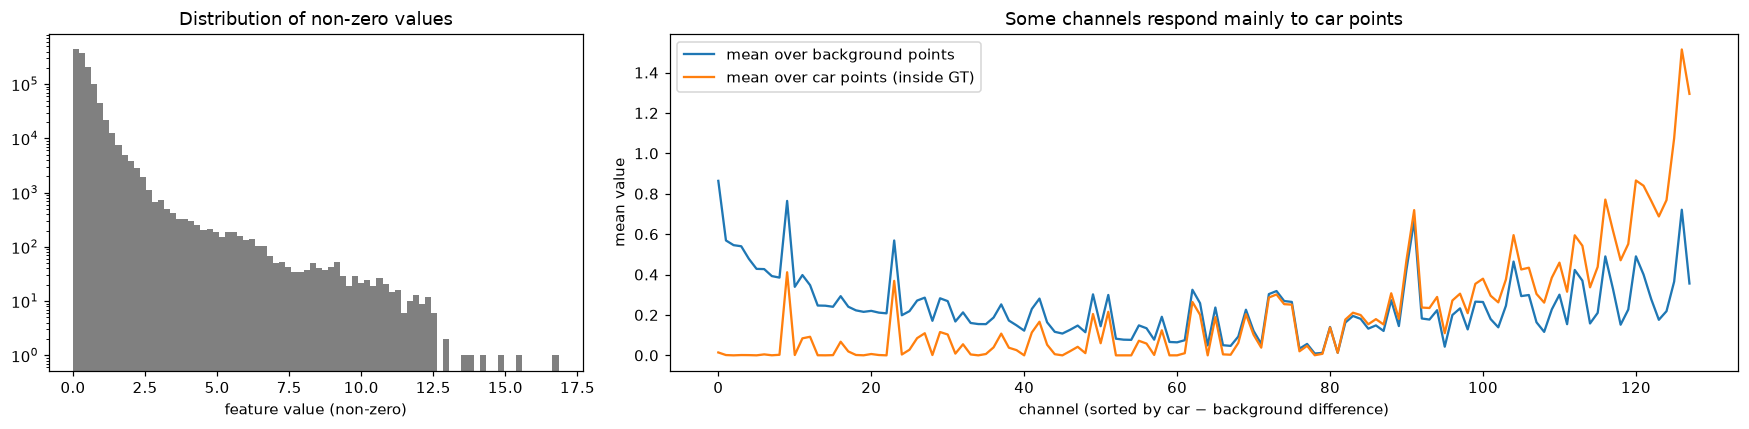

In [14]:
print(f'features: shape {feat.shape}, min {feat.min():.2f}, max {feat.max():.2f}, mean {feat.mean():.3f}')
print(f'exact zeros: {100 * (feat == 0).mean():.1f}% (the backbone ends with a ReLU, so values are never negative)')
dead = (feat == 0).all(0)
print(f'channels that are 0 for every point of this frame: {dead.sum()}')

fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [1, 2]})
axes[0].hist(feat[feat > 0].ravel(), bins=80, color='gray', log=True)
axes[0].set_xlabel('feature value (non-zero)'); axes[0].set_title('Distribution of non-zero values')

ch_mean_car, ch_mean_bg = feat[in_gt].mean(0), feat[~in_gt].mean(0)
order = np.argsort(ch_mean_car - ch_mean_bg)
axes[1].plot(ch_mean_bg[order], label='mean over background points')
axes[1].plot(ch_mean_car[order], label='mean over car points (inside GT)')
axes[1].set_xlabel('channel (sorted by car − background difference)'); axes[1].set_ylabel('mean value')
axes[1].set_title('Some channels respond mainly to car points'); axes[1].legend()
plt.tight_layout(); plt.show()

### CAPIRE MEGLIO QUESTO PEZZO

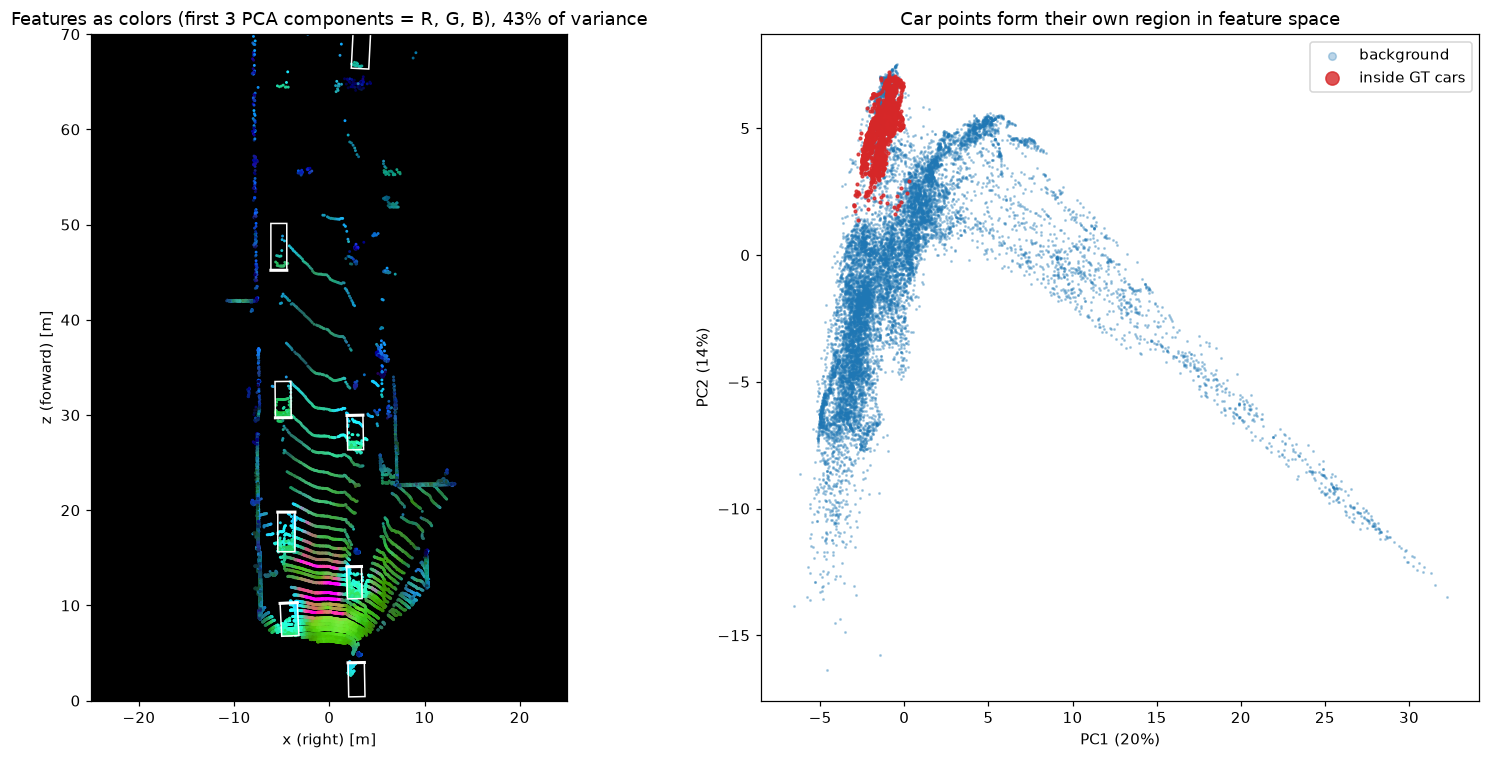

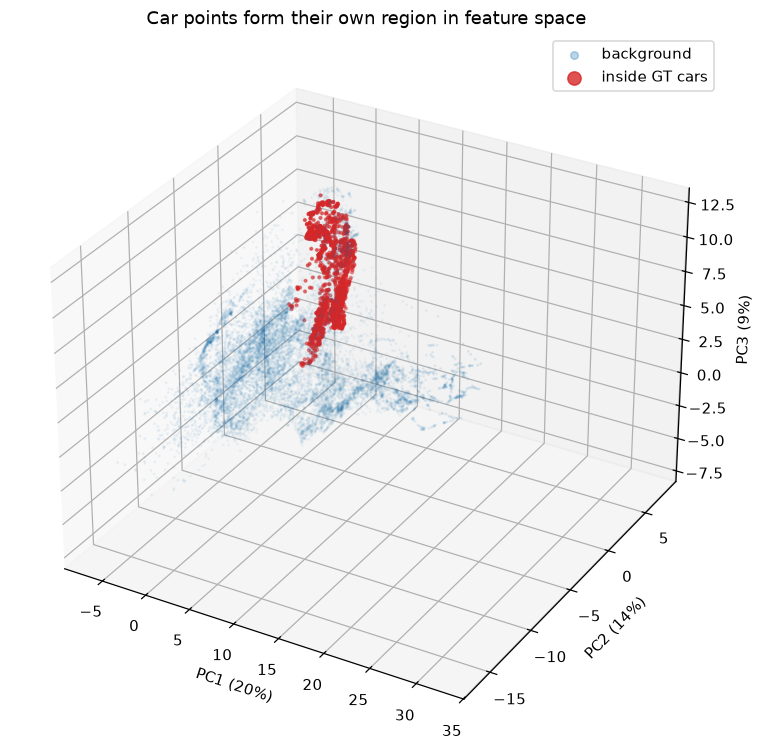

In [32]:
# PCA: squeeze the 128 numbers into 3 directions of largest variation, then show them as RGB colors.
# Each channel is log-scaled and standardized first, so a few very large values don't dominate.
X = np.log1p(feat)
X = (X - X.mean(0)) / (X.std(0) + 1e-6)
_, S, Vt = np.linalg.svd(X[::4], full_matrices=False)     # every 4th point is enough to find the directions
pcs = X @ Vt[:3].T
explained = S[:3] ** 2 / (S ** 2).sum()
rgb = (pcs - np.percentile(pcs, 2, 0)) / (np.percentile(pcs, 98, 0) - np.percentile(pcs, 2, 0))
rgb = np.clip(rgb, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
ax.scatter(xyz[:, 0], xyz[:, 2], c=rgb, s=0.8)
draw_bev_boxes(ax, tgt, 'white', lw=1)
ax.set_facecolor('black')
bev(ax, f'Features as colors (first 3 PCA components = R, G, B), {100 * explained.sum():.0f}% of variance')

ax = axes[1]
ax.scatter(pcs[~in_gt, 0], pcs[~in_gt, 1], s=1, alpha=.3, label='background', color='tab:blue')
ax.scatter(pcs[in_gt, 0], pcs[in_gt, 1], s=3, alpha=.8, label='inside GT cars', color='tab:red')
ax.set_xlabel(f'PC1 ({100 * explained[0]:.0f}%)'); ax.set_ylabel(f'PC2 ({100 * explained[1]:.0f}%)')
ax.set_title('Car points form their own region in feature space'); ax.legend(markerscale=5)
plt.tight_layout(); plt.show()




fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pcs[~in_gt, 0], pcs[~in_gt, 1], pcs[~in_gt, 2],
           s=1, alpha=.3, label='background', color='tab:blue')
ax.scatter(pcs[in_gt, 0], pcs[in_gt, 1], pcs[in_gt, 2],
           s=3, alpha=.8, label='inside GT cars', color='tab:red')

ax.set_xlabel(f'PC1 ({100 * explained[0]:.0f}%)')
ax.set_ylabel(f'PC2 ({100 * explained[1]:.0f}%)')
ax.set_zlabel(f'PC3 ({100 * explained[2]:.0f}%)')
ax.set_title('Car points form their own region in feature space')
ax.legend(markerscale=5)
plt.tight_layout(); plt.show()

Points on the same kind of surface get similar colors: road (green to magenta), walls and poles (blue), cars (bright cyan patches inside the boxes). The features were only trained to find cars, yet they also encode what other surfaces are. In the PCA plot, car points sit in their own region, which is what makes them easy for the second stage to work with.

## 6. Ground truth: what cars look like in KITTI

Statistics over all ground-truth cars in the split. The difficulty levels follow `utils/eval.py → clean_data`, the official KITTI rules:

| Level | Min 2D box height | Max occlusion | Max truncation |
|---|---|---|---|
| easy | > 40 px | 0 (fully visible) | 0.15 |
| moderate | > 25 px | 1 (partly occluded) | 0.30 |
| hard | > 25 px | 2 (largely occluded) | 0.50 |

A car that fails all three is ignored by the evaluation (it's neither rewarded nor punished).

In [16]:
def difficulty(t):
    '''KITTI difficulty of raw 15-column labels: 0 easy, 1 moderate, 2 hard, -1 ignored.'''
    height = t[:, 6] - t[:, 4]
    level = np.full(len(t), -1)
    for d, (min_h, max_occ, max_tr) in reversed(list(enumerate([(40, 0, .15), (25, 1, .3), (25, 2, .5)]))):
        ok = (height > min_h) & (t[:, 1] <= max_occ) & (t[:, 0] <= max_tr)
        level[ok] = d
    return level


all_gt = np.concatenate([h5[fr]['target'][()] for fr in frames])
gt = pd.DataFrame(all_gt, columns=KITTI_COLS)
gt['distance'] = np.hypot(gt.x, gt.z)
gt['difficulty'] = pd.Categorical.from_codes(difficulty(all_gt) + 1, ['ignored', 'easy', 'moderate', 'hard'])
print(f'{len(gt)} ground-truth cars in {len(frames)} frames\n')
print(gt['difficulty'].value_counts().reindex(['easy', 'moderate', 'hard', 'ignored']).to_string(), '\n')
gt[['h', 'w', 'l', 'distance', 'rotation_y', 'truncated', 'occluded']].describe().round(2)

936 ground-truth cars in 250 frames

difficulty
easy        188
moderate    335
hard        183
ignored     230 



,h,w,l,distance,rotation_y,truncated,occluded
count,936.00,936.00,936.00,936.00,936.00,936.00,936.00
mean,1.53,1.64,3.87,27.96,-0.28,0.09,0.80
std,0.14,0.09,0.41,15.82,1.69,0.25,0.89
min,1.22,1.28,2.47,2.65,-3.14,0.00,0.00
25%,1.43,1.57,3.59,15.92,-1.59,0.00,0.00
50%,1.50,1.64,3.85,25.11,-1.49,0.00,1.00
75%,1.60,1.69,4.15,37.66,1.55,0.00,1.00
max,2.21,2.04,5.10,74.36,3.13,1.00,3.00


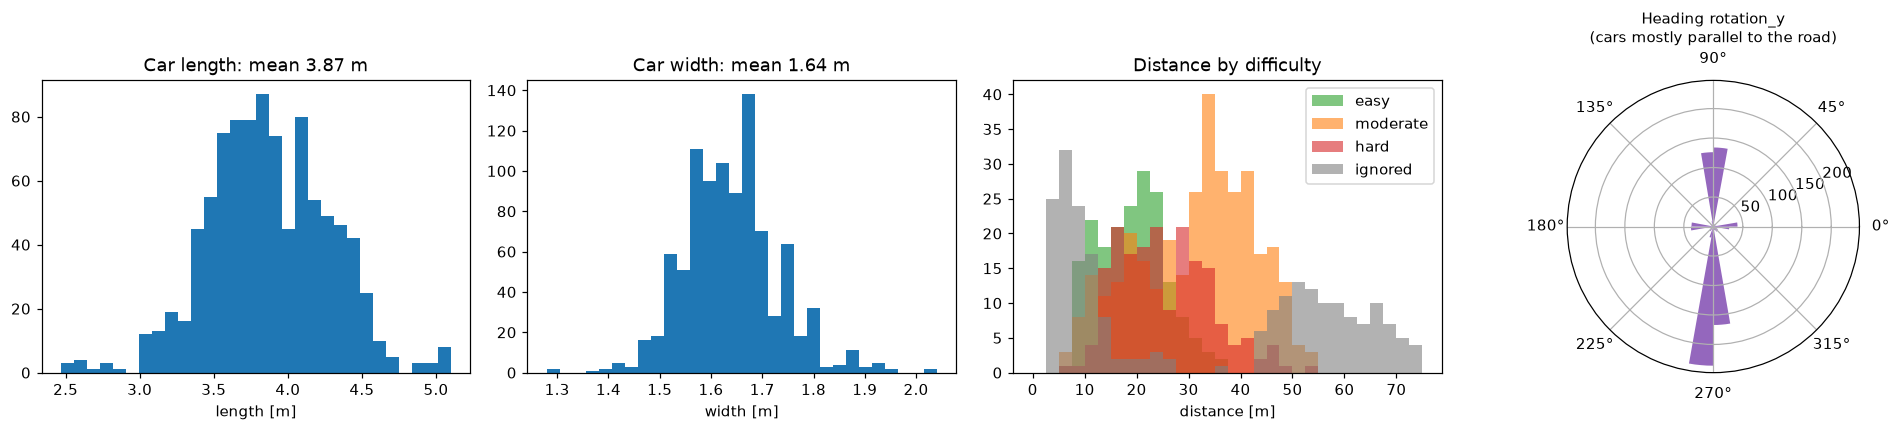

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (col, label) in zip(axes[:2], [('l', 'length'), ('w', 'width')]):
    ax.hist(gt[col], bins=30, color='tab:blue')
    ax.set_xlabel(f'{label} [m]'); ax.set_title(f'Car {label}: mean {gt[col].mean():.2f} m')

colors = {'easy': 'tab:green', 'moderate': 'tab:orange', 'hard': 'tab:red', 'ignored': 'gray'}
for name in colors:
    sel = gt['difficulty'] == name
    axes[2].hist(gt.loc[sel, 'distance'], bins=30, range=(0, 75), alpha=.6, label=name, color=colors[name])
axes[2].set_xlabel('distance [m]'); axes[2].set_title('Distance by difficulty'); axes[2].legend()

ax = fig.add_subplot(1, 4, 4, projection='polar'); axes[3].remove()
ax.hist(gt['rotation_y'], bins=36, color='tab:purple')
ax.set_title('Heading rotation_y\n(cars mostly parallel to the road)', fontsize=10)
plt.tight_layout(); plt.show()

## 7. Proposals: the coarse boxes from stage 1

Every frame has exactly 100 proposals in minival/val (300 per frame in train). Many overlap: the first stage's NMS used a loose threshold, so several proposals cover the same car. Removing the duplicates is the job of the final NMS (Task 2.5).

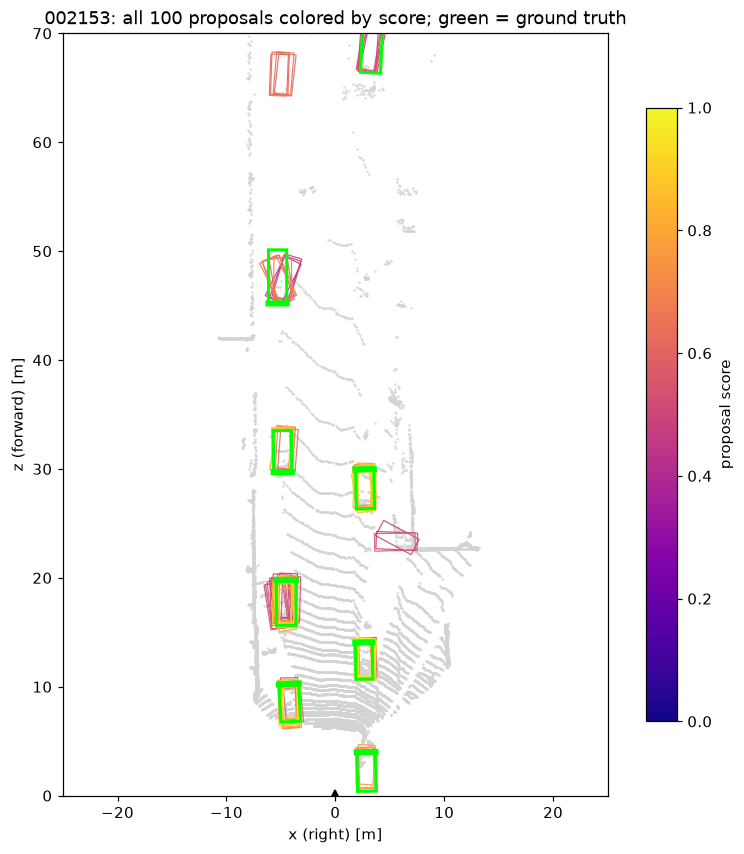

In [18]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(xyz[:, 0], xyz[:, 2], c='lightgray', s=0.3)
order = np.argsort(det_score)
cmap = plt.get_cmap('plasma')
for b, s in zip(det[order], det_score[order]):
    draw_bev_boxes(ax, b, cmap(s), lw=0.8, alpha=0.9, front=False)
draw_bev_boxes(ax, tgt, 'lime', lw=2)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1)); fig.colorbar(sm, ax=ax, label='proposal score', fraction=0.04)
bev(ax, f'{FRAME}: all {len(det)} proposals colored by score; green = ground truth')
plt.show()

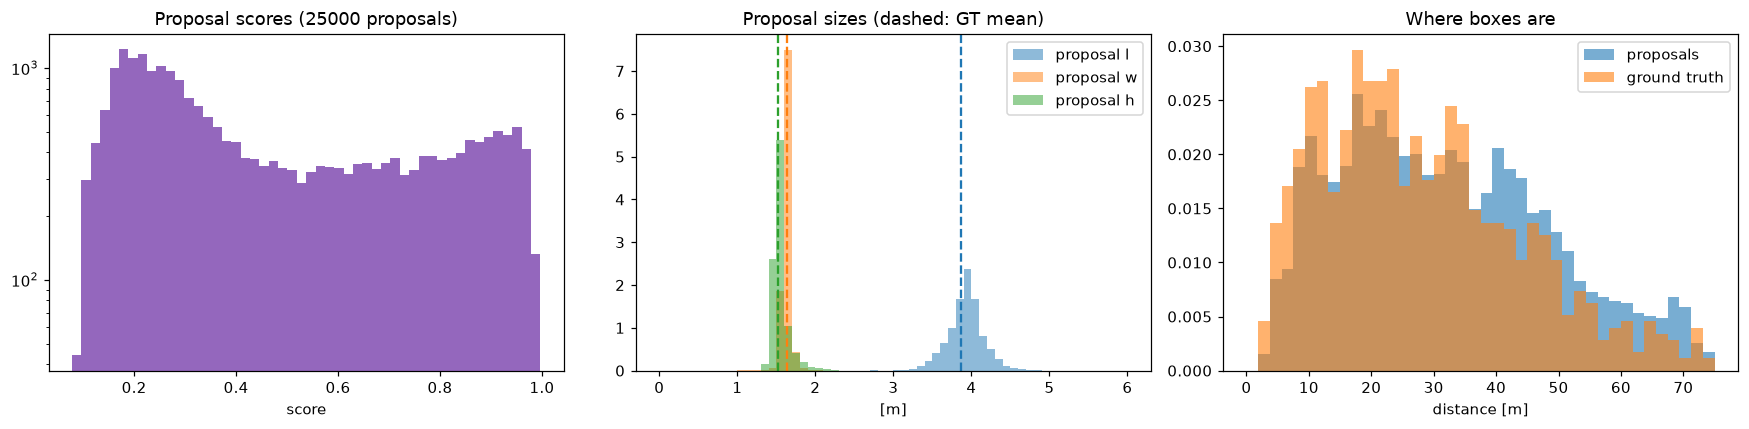

In [19]:
all_det = np.concatenate([h5[fr]['detections'][()] for fr in frames])
all_det = all_det[np.abs(all_det).sum(1) > 0]
pr = pd.DataFrame(all_det, columns=KITTI_COLS)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(pr['score'], bins=50, color='tab:purple', log=True)
axes[0].set_xlabel('score'); axes[0].set_title(f'Proposal scores ({len(pr)} proposals)')
for col, c in [('l', 'tab:blue'), ('w', 'tab:orange'), ('h', 'tab:green')]:
    axes[1].hist(pr[col], bins=60, range=(0, 6), alpha=.5, density=True, color=c, label=f'proposal {col}')
    axes[1].axvline(gt[col].mean(), color=c, ls='--')
axes[1].set_xlabel('[m]'); axes[1].set_title('Proposal sizes (dashed: GT mean)'); axes[1].legend()
axes[2].hist(np.hypot(pr.x, pr.z), bins=40, range=(0, 75), alpha=.6, density=True, label='proposals')
axes[2].hist(gt['distance'], bins=40, range=(0, 75), alpha=.6, density=True, label='ground truth')
axes[2].set_xlabel('distance [m]'); axes[2].set_title('Where boxes are'); axes[2].legend()
plt.tight_layout(); plt.show()

## 8. How good are the proposals? IoU and recall

A proposal **matches** a car when their 3D boxes overlap enough, measured by the **Intersection over Union (IoU): OVERLAP VOLUME ÷ COMBINED VOLUME**. Task 2.1 asks for the **recall** at IoU ≥ 0.5: the share of cars that have at least one proposal that good.

The helper below computes 3D IoU with `shapely` (rotated top-view polygons × vertical overlap). It's slow but simple, fine for exploration. Task 2.1 will implement its own, faster `get_iou`, and this one can serve as a reference to check it against.

In [20]:
def bev_polygons(boxes):
    return shapely.polygons(box_corners(boxes)[:, [4, 5, 6, 7]][:, :, [0, 2]])


def iou3d(a, b):
    '''Pairwise 3D IoU between boxes a (N, 7) and b (M, 7), camera frame.'''
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    pa, pb = bev_polygons(a), bev_polygons(b)
    inter_bev = shapely.area(shapely.intersection(pa[:, None], pb[None, :]))
    # vertical extent: y points down, the box spans [y - h, y]
    top = np.maximum(a[:, None, 1] - a[:, None, 3], b[None, :, 1] - b[None, :, 3])
    bottom = np.minimum(a[:, None, 1], b[None, :, 1])
    inter = inter_bev * np.clip(bottom - top, 0, None)
    vol_a, vol_b = a[:, 3] * a[:, 4] * a[:, 5], b[:, 3] * b[:, 4] * b[:, 5]
    return inter / (vol_a[:, None] + vol_b[None, :] - inter)


iou = iou3d(det, tgt)            # (proposals, cars)
best_per_car = iou.max(0)
print(f'frame {FRAME}: best proposal IoU for each car:', best_per_car.round(2))
print(f'recall@0.5 = {np.mean(best_per_car >= 0.5):.2f}')

frame 002153: best proposal IoU for each car: [0.79 0.8  0.87 0.85 0.82 0.51 0.69 0.82]
recall@0.5 = 1.00


In [21]:
# Over the whole split: best IoU per car, recall, and recall when only the top-k proposals (by score) are kept
best, levels, best_topk = [], [], {k: [] for k in [5, 10, 20, 50, 100]}
fg = hard_bg = easy_bg = between = 0
cfg = {'t_fg_lb': 0.55, 't_bg_up': 0.45, 't_bg_hard_lb': 0.05}     # thresholds from config.yaml (Task 2.3)
for i, fr in enumerate(frames):
    t = ds.get_data(i, 'target')
    if t[0, 3] == -100:
        t = np.zeros((0, 7))
    d = ds.get_data(i, 'detections')
    s = h5[fr]['detections'][()]; s = s[np.abs(s).sum(1) > 0, 14]
    m = iou3d(d, t)
    if len(t):
        best.extend(m.max(0))
        levels.extend(difficulty(h5[fr]['target'][()]))
        rank = np.argsort(-s)
        for k in best_topk:
            best_topk[k].extend(m[rank[:k]].max(0))
    # Task 2.3 preview: how each proposal would be classified by its best IoU with any car
    p_best = m.max(1) if len(t) else np.zeros(len(d))
    fg += (p_best >= cfg['t_fg_lb']).sum()
    between += ((p_best >= cfg['t_bg_up']) & (p_best < cfg['t_fg_lb'])).sum()
    hard_bg += ((p_best >= cfg['t_bg_hard_lb']) & (p_best < cfg['t_bg_up'])).sum()
    easy_bg += (p_best < cfg['t_bg_hard_lb']).sum()
best, levels = np.array(best), np.array(levels)

print(f'recall@0.5 over {len(best)} cars: {np.mean(best >= 0.5):.3f}   recall@0.7: {np.mean(best >= 0.7):.3f}\n')
names = {0: 'easy', 1: 'moderate', 2: 'hard', -1: 'ignored'}
print(pd.DataFrame([{'difficulty': names[d], 'cars': (levels == d).sum(),
                     'recall@0.5': np.mean(best[levels == d] >= 0.5), 'recall@0.7': np.mean(best[levels == d] >= 0.7),
                     'no proposal at all (IoU < 0.05)': (best[levels == d] < 0.05).sum()}
                    for d in [0, 1, 2, -1]]).set_index('difficulty').round(3).to_string())
print('\nproposals per class (Task 2.3 preview):')
total = fg + between + hard_bg + easy_bg
for name, n in [('foreground  (IoU >= 0.55)', fg), ('ignored     (0.45-0.55)', between),
                ('hard bg     (0.05-0.45)', hard_bg), ('easy bg     (IoU < 0.05)', easy_bg)]:
    print(f'  {name}: {n:6d}  ({100 * n / total:.1f}%)')

recall@0.5 over 936 cars: 0.922   recall@0.7: 0.786

            cars  recall@0.5  recall@0.7  no proposal at all (IoU < 0.05)
difficulty                                                               
easy         188       1.000       0.979                                0
moderate     335       0.988       0.842                                0
hard         183       0.880       0.738                               13
ignored      230       0.796       0.587                               30

proposals per class (Task 2.3 preview):
  foreground  (IoU >= 0.55):   7701  (30.8%)
  ignored     (0.45-0.55):   1543  (6.2%)
  hard bg     (0.05-0.45):   2162  (8.6%)
  easy bg     (IoU < 0.05):  13594  (54.4%)


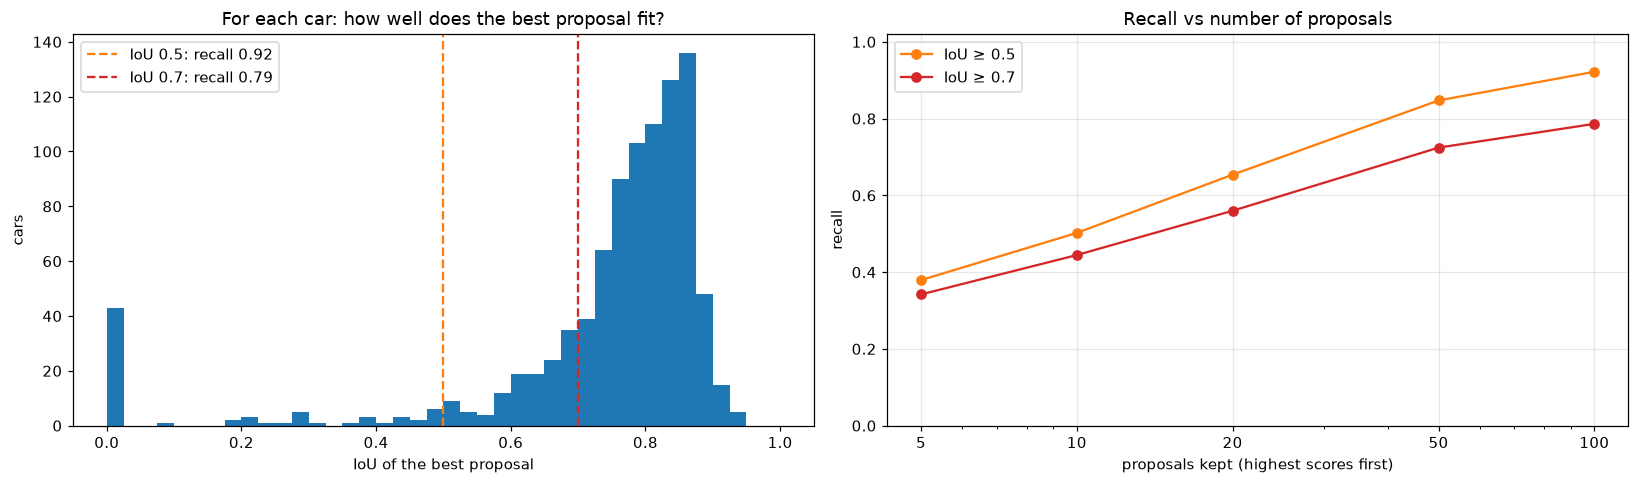

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(best, bins=40, range=(0, 1), color='tab:blue')
for t, c in [(0.5, 'tab:orange'), (0.7, 'tab:red')]:
    axes[0].axvline(t, color=c, ls='--', label=f'IoU {t}: recall {np.mean(best >= t):.2f}')
axes[0].set_xlabel('IoU of the best proposal'); axes[0].set_ylabel('cars'); axes[0].legend()
axes[0].set_title('For each car: how well does the best proposal fit?')

ks = list(best_topk)
for t, c in [(0.5, 'tab:orange'), (0.7, 'tab:red')]:
    axes[1].plot(ks, [np.mean(np.array(best_topk[k]) >= t) for k in ks], 'o-', color=c, label=f'IoU ≥ {t}')
axes[1].set_xscale('log'); axes[1].set_xticks(ks, ks); axes[1].set_ylim(0, 1.02); axes[1].grid(alpha=.3)
axes[1].set_xlabel('proposals kept (highest scores first)'); axes[1].set_ylabel('recall'); axes[1].legend()
axes[1].set_title('Recall vs number of proposals')
plt.tight_layout(); plt.show()

How to read this:
* **Recall at 0.5 is high**, especially for easy and moderate cars: almost every car the evaluation counts has a proposal in roughly the right place. That's what a first stage must deliver, and it's why Task 2.1 checks recall: **a car with no proposal can't be recovered by stage 2**, which only refines existing proposals.
* The cars with no proposal at all (the bar at IoU 0) are mostly *ignored* or *hard* ones: far away, heavily occluded or truncated, with very few points.
* **Recall at 0.7 is clearly lower than at 0.5.** 0.7 is the official KITTI threshold for cars, so about one car in five has a proposal that is in the right place but not precise enough. **Tightening those boxes is the second stage's job.**
* **Recall vs number of proposals:** with only the 10 highest-scoring proposals, half the cars are missed. The scores alone don't rank proposals well enough, which is why stage 2 also learns a new confidence score (and why stage 1 keeps 100–300 proposals).
* The class split previews Task 2.3: most proposals are background, which is why training samples a fixed mix of foreground, hard and easy background.

## 9. Preview of Task 2.2: points around each proposal

The second stage only looks at the points near one proposal: the box enlarged by δ = 1 m on every side (`config.yaml → data.delta`). Task 2.2 then samples or repeats those points to exactly 512 (`max_points`).

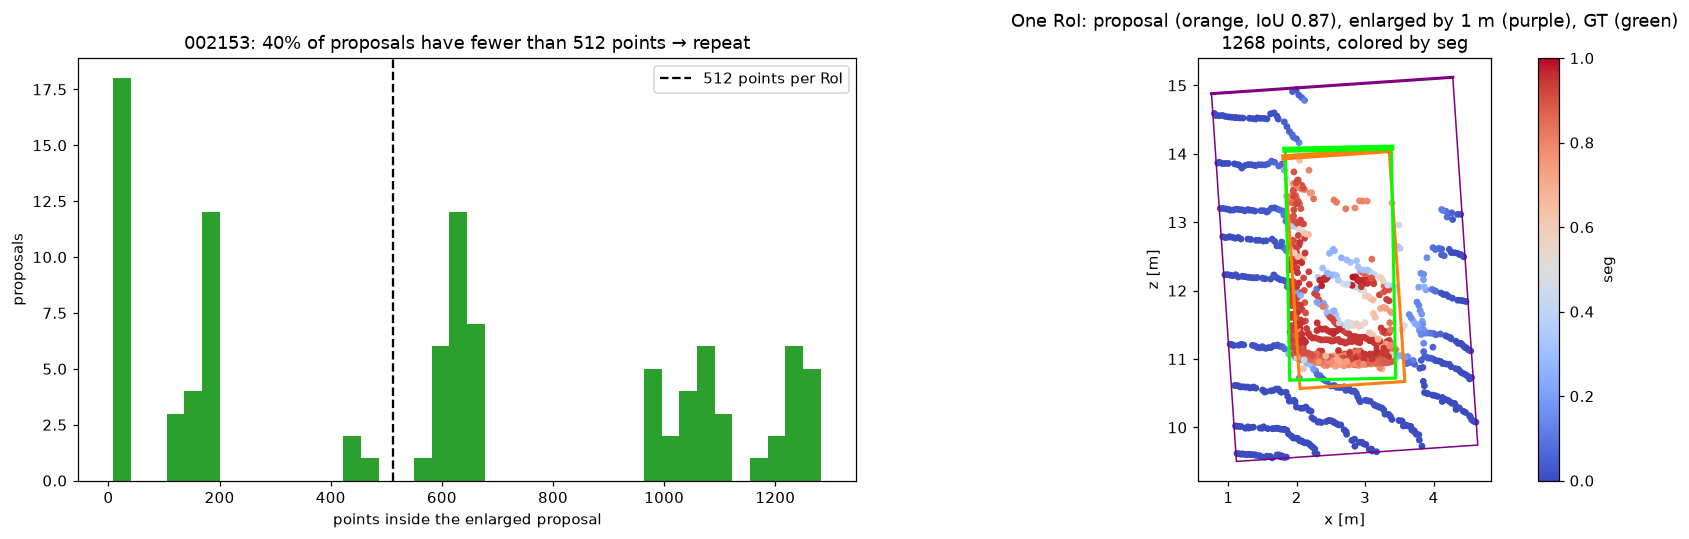

In [33]:
n_in = points_in_boxes(xyz, det, enlarge=1.0).sum(0)
best_iou_prop = iou.max(1) if len(tgt) else np.zeros(len(det))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.2]})
axes[0].hist(n_in, bins=40, color='tab:green')
axes[0].axvline(512, color='k', ls='--', label='512 points per RoI')
axes[0].set_xlabel('points inside the enlarged proposal'); axes[0].set_ylabel('proposals')
axes[0].set_title(f'{FRAME}: {np.mean(n_in < 512) * 100:.0f}% of proposals have fewer than 512 points → repeat')
axes[0].legend()

k = int(np.argmax(best_iou_prop))           # proposal that best matches a car
b = det[k]
mask = points_in_boxes(xyz, b[None], enlarge=1.0)[:, 0]
ax = axes[1]
sc = ax.scatter(xyz[mask, 0], xyz[mask, 2], c=seg[mask], cmap='coolwarm', vmin=0, vmax=1, s=12)
enlarged = b.copy(); enlarged[1] += 1.0; enlarged[3:6] += 2.0
draw_bev_boxes(ax, enlarged, 'purple', lw=1)
draw_bev_boxes(ax, b, 'tab:orange', lw=2)
j = int(np.argmax(iou[k])); draw_bev_boxes(ax, tgt[j], 'lime', lw=2)
ax.set_aspect('equal'); ax.set_xlabel('x [m]'); ax.set_ylabel('z [m]')
ax.set_title(f'One RoI: proposal (orange, IoU {iou[k, j]:.2f}), enlarged by 1 m (purple), GT (green)\n'
             f'{mask.sum()} points, colored by seg')
fig.colorbar(sc, ax=ax, label='seg', fraction=0.04)
plt.tight_layout(); plt.show()

## 10. The frame in 3D

Same vispy approach as Problem 1, Task 1.3. Points are colored by `seg` (red = car), ground truth is green, and the 10 best-scoring proposals are orange. vispy expects z up, so the camera-frame points are re-ordered for display: (forward, left, up) = (z, −x, −y).

Set `INTERACTIVE = True` to open a window you can rotate and zoom. Close it to continue.

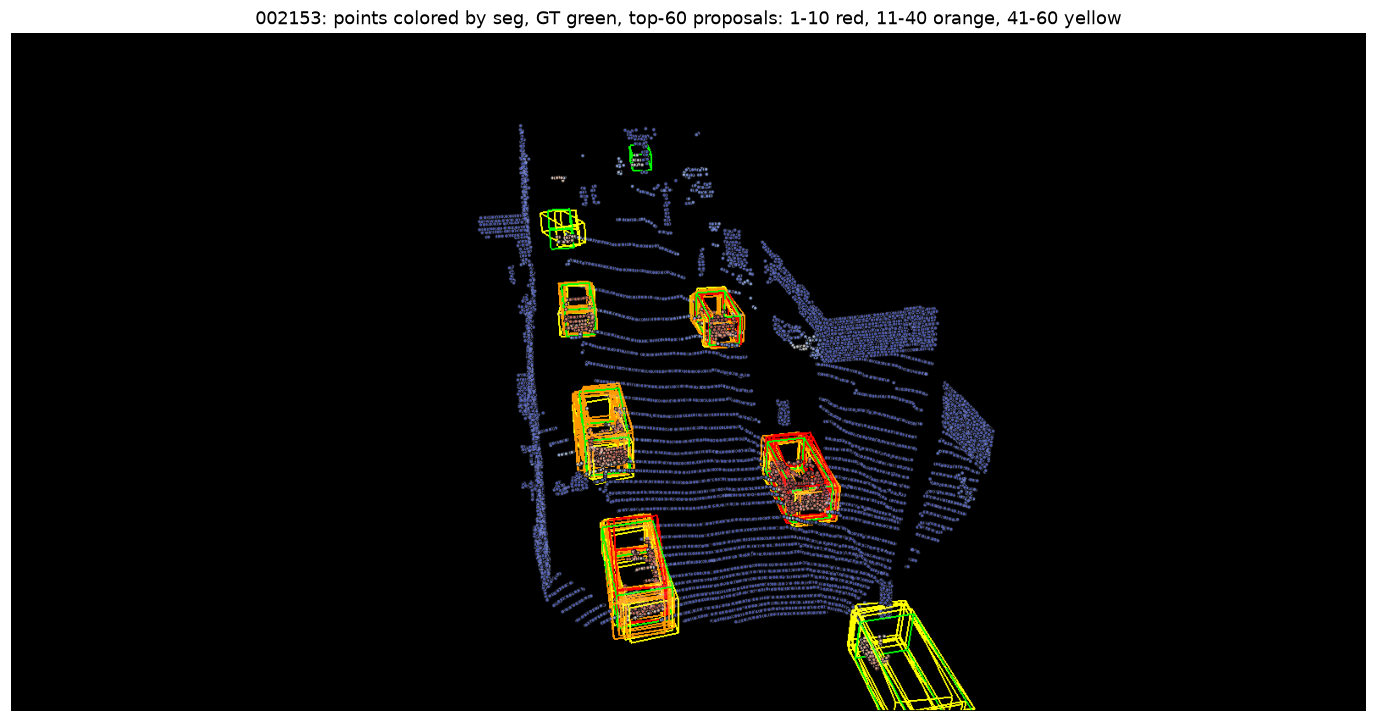

In [35]:
import vispy
vispy.use('pyqt6')
from vispy.scene import SceneCanvas, visuals, cameras

EDGES = np.array([(0, 1), (0, 3), (0, 4), (2, 1), (2, 3), (2, 6), (5, 1), (5, 4), (5, 6), (7, 3), (7, 4), (7, 6)])
to_display = lambda p: np.stack([p[..., 2], -p[..., 0], -p[..., 1]], -1)


def scene_3d(show=False, n_top=60):
    canvas = SceneCanvas(keys='interactive', show=show, size=(1600, 800), bgcolor='black')
    view = canvas.central_widget.add_view()
    view.camera = cameras.TurntableCamera(up='z', azimuth=-100, elevation=28, distance=40, center=(22, 0, -1))
    colors = plt.get_cmap('coolwarm')(seg)
    markers = visuals.Markers(); markers.set_data(to_display(xyz), face_color=colors, edge_width=0, size=3)
    view.add(markers)

    order = np.argsort(-det_score)[:n_top]          # indices sorted by score, best first
    groups = [
        (tgt,              (0, 1, 0, 1)),           # GT: green
        (det[order[:10]],   (1, 0, 0, 1)),          # ranks 1-10: red
        (det[order[10:40]], (1, .6, 0, 1)),         # ranks 11-40: orange
        (det[order[40:60]], (1, 1, 0, 1)),          # ranks 41-60: yellow
    ]
    for boxes, color in groups:
        if len(boxes):
            c = to_display(box_corners(boxes))
            connect = np.concatenate([EDGES + 8 * i for i in range(len(c))])
            line = visuals.Line(); line.set_data(c.reshape(-1, 3), connect=connect, color=color, width=2)
            view.add(line)
    return canvas


img3d = scene_3d().render()
plt.figure(figsize=(16, 8)); plt.imshow(img3d); plt.axis('off')
plt.title(f'{FRAME}: points colored by seg, GT green, top-60 proposals: 1-10 red, 11-40 orange, 41-60 yellow')
plt.show()

INTERACTIVE = False
if INTERACTIVE:
    win = scene_3d(show=True)
    vispy.app.run()

## Summary

* Each frame is a camera-view crop of the KITTI scan: 16,384 points with intensity, a car probability (`seg`) and 128 learned features, plus 100 proposals and the ground-truth cars.
* Stage 1 already separates car points well (`seg`, and the feature PCA). Its proposals cover about 92% of cars at IoU 0.5 (more for easy/moderate cars), fewer at the stricter 0.7, and their scores rank them poorly.
* The second stage's job is to turn "roughly right" into "precise": pool each proposal's neighborhood (Task 2.2), train on a balanced mix of proposals (Task 2.3) with box-regression and confidence losses (Task 2.4), then remove duplicates with NMS (Task 2.5).